# 04 — Evaluation, Choosing a Cutoff, and What It Means

**AAI-500 Final Team Project, Group 02 — Predicting Credit Card Default**

Names: Abhineet Sood, Ravi Kanth Vuddagiri
Date: October 4, 2026

Notebook 03 picked two finalists using cross-validation on the training set:

- **Logistic regression (our features):** the model we can explain
- **Random forest:** the model with the best score

Here we score them on the **test set** (8,990 clients the models have never seen), then choose a cutoff
(threshold) based on what each kind of mistake costs a lender.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import PROCESSED_DIR

plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 14,
                     "axes.labelsize": 12, "legend.fontsize": 11})
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"

LOGIT = "Logistic regression (our features)"
RF = "Random forest"

## 1. Load the predictions
Both files come from notebook 03. Each column is one model's predicted probability of default.

In [2]:
test_pred = pd.read_csv(PROCESSED_DIR / "test_predictions.csv")
oof = pd.read_csv(PROCESSED_DIR / "train_oof_predictions.csv")
y_test = test_pred["y"]
model_names = [c for c in test_pred.columns if c != "y"]

print("Test clients =", len(test_pred))
print("Defaults in the test set =", y_test.sum(), " rate =", round(y_test.mean(), 4))

Test clients = 8990
Defaults in the test set = 1989  rate = 0.2212


## 2. Test-set results at the usual 0.5 cutoff
If a model's probability is 0.5 or more, we predict "default".

- **Accuracy:** share of all clients predicted correctly. This is misleading here, since always saying
  "no default" already gets about 78%.
- **Precision:** of the clients we flag, how many actually default.
- **Recall:** of the clients who actually default, how many we flag.
- **F1:** one number that balances precision and recall.
- **ROC-AUC:** how well the model ranks defaulters above non-defaulters (doesn't need a cutoff).

In [3]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

def results_at(y, prob, cutoff):
    pred = (prob >= cutoff).astype(int)
    return {"roc_auc": roc_auc_score(y, prob),
            "accuracy": accuracy_score(y, pred),
            "precision": precision_score(y, pred),
            "recall": recall_score(y, pred),
            "f1": f1_score(y, pred),
            "share_flagged": pred.mean()}

rows = {}
for name in model_names:
    rows[name] = results_at(y_test, test_pred[name], 0.5)
test_results = pd.DataFrame(rows).T.sort_values("roc_auc", ascending=False)
test_results.round(3).to_csv(TABLE_DIR / "test_results_cutoff_0.5.csv")
test_results.round(3)

,roc_auc,accuracy,precision,recall,f1,share_flagged
Gradient boosting,0.773,0.816,0.658,0.355,0.461,0.119
Random forest,0.773,0.814,0.652,0.346,0.452,0.118
Logistic regression (our features),0.764,0.814,0.654,0.338,0.445,0.114
Decision tree,0.750,0.815,0.664,0.332,0.443,0.111
Logistic regression (raw columns),0.708,0.807,0.679,0.242,0.357,0.079


- On ROC-AUC, **random forest and gradient boosting tie at 0.773**, and our **logistic regression gets
  0.764**. These are close to the cross-validation scores from notebook 03 (0.787 and 0.776), so the
  models weren't overfit to the training data.
- At the 0.5 cutoff, every model has low **recall: only 33–36% of defaulters get flagged**. Accuracy is
  about 81%, only 3 points better than always guessing "no default".
- That's not because the models are bad at ranking clients. It's because 0.5 is the wrong cutoff when only
  22% of clients default and missing a defaulter is expensive. Section 5 fixes this.

## 3. ROC curves
An ROC curve shows every possible cutoff at once: how many defaulters we catch (up) vs. how many good
clients we wrongly flag (right). The closer the curve is to the top-left corner, the better.

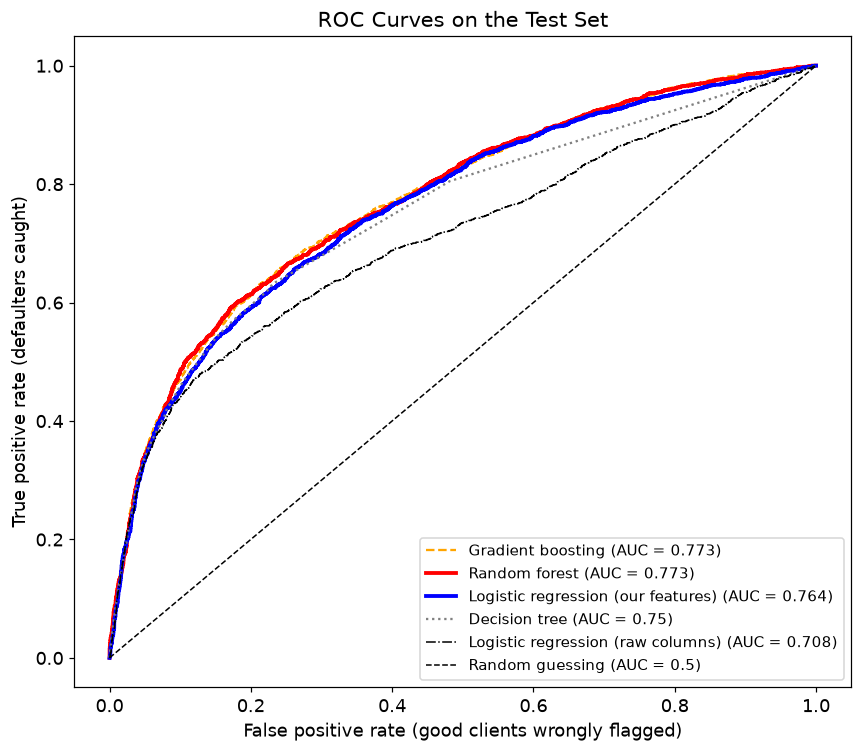

In [4]:
from sklearn.metrics import roc_curve

styles = {LOGIT: ("blue", "-", 2.5), RF: ("red", "-", 2.5), "Gradient boosting": ("orange", "--", 1.5),
          "Decision tree": ("gray", ":", 1.5), "Logistic regression (raw columns)": ("black", "-.", 1)}

plt.figure(figsize=(8, 7))
for name in test_results.index:
    fpr, tpr, cutoffs = roc_curve(y_test, test_pred[name])
    color, line, width = styles[name]
    plt.plot(fpr, tpr, color=color, linestyle=line, linewidth=width,
             label=name + " (AUC = " + str(round(test_results.loc[name, "roc_auc"], 3)) + ")")
plt.plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=1, label="Random guessing (AUC = 0.5)")
plt.xlabel("False positive rate (good clients wrongly flagged)")
plt.ylabel("True positive rate (defaulters caught)")
plt.title("ROC Curves on the Test Set")
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.savefig(FIG_DIR / "roc_curves.png", dpi=150)
plt.show()

The curves for the random forest, gradient boosting and our logistic regression are almost on top of each
other. All of them are well above the diagonal line, which is what random guessing would give.

## 4. Is the random forest really better? Bootstrap confidence intervals
The test set is just one sample of clients, so its AUC has sampling error. We use the bootstrap: resample
the test set with replacement 2,000 times, recompute each AUC, and take the middle 95% of the results as
a confidence interval. We use the **same** resampled clients for both models, so we can also get a CI for
the **difference**.

In [5]:
rng = np.random.default_rng(500)
n = len(y_test)
y_arr = y_test.to_numpy()
p_logit = test_pred[LOGIT].to_numpy()
p_rf = test_pred[RF].to_numpy()

boot_logit = []
boot_rf = []
boot_diff = []
for i in range(2000):
    idx = rng.integers(0, n, n)
    auc_logit = roc_auc_score(y_arr[idx], p_logit[idx])
    auc_rf = roc_auc_score(y_arr[idx], p_rf[idx])
    boot_logit.append(auc_logit)
    boot_rf.append(auc_rf)
    boot_diff.append(auc_rf - auc_logit)

print("Logistic regression AUC: 95% CI =", np.round(np.percentile(boot_logit, [2.5, 97.5]), 3))
print("Random forest AUC:       95% CI =", np.round(np.percentile(boot_rf, [2.5, 97.5]), 3))
print("Difference (RF - logistic): 95% CI =", np.round(np.percentile(boot_diff, [2.5, 97.5]), 3))
print("Share of resamples where RF is higher =", round(np.mean(np.array(boot_diff) > 0), 3))

Logistic regression AUC: 95% CI = [0.751 0.776]
Random forest AUC:       95% CI = [0.761 0.785]
Difference (RF - logistic): 95% CI = [0.003 0.015]
Share of resamples where RF is higher = 0.998


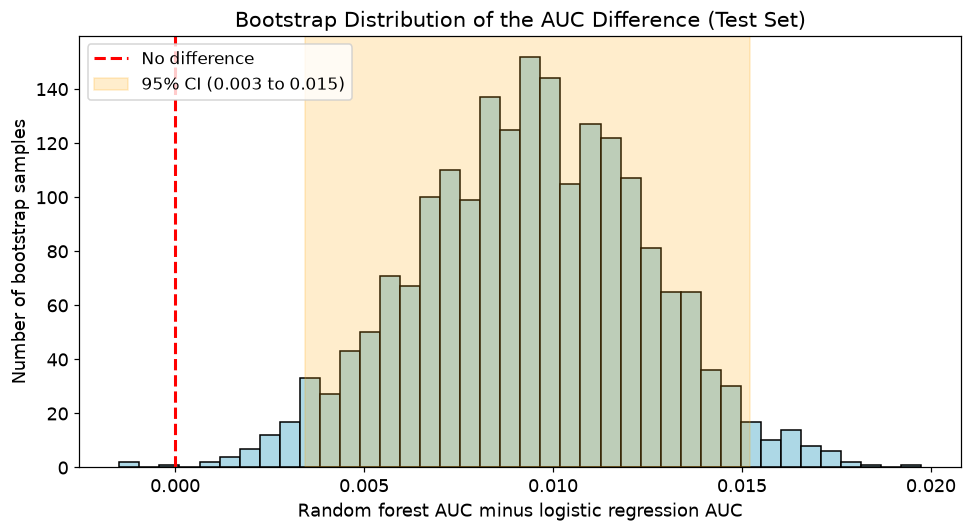

In [6]:
low, high = np.percentile(boot_diff, [2.5, 97.5])

plt.figure(figsize=(9, 5))
plt.hist(boot_diff, bins=40, color="lightblue", edgecolor="black")
plt.axvline(0, color="red", linestyle="--", linewidth=2, label="No difference")
plt.axvspan(low, high, color="orange", alpha=0.2,
            label="95% CI (" + str(round(low, 3)) + " to " + str(round(high, 3)) + ")")
plt.xlabel("Random forest AUC minus logistic regression AUC")
plt.ylabel("Number of bootstrap samples")
plt.title("Bootstrap Distribution of the AUC Difference (Test Set)")
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "bootstrap_auc_difference.png", dpi=150)
plt.show()

- Logistic regression test AUC: **0.764**, 95% CI **0.751 to 0.776**
- Random forest test AUC: **0.773**, 95% CI **0.761 to 0.785**
- Difference: 95% CI **0.003 to 0.015**. The interval doesn't include 0, and the random forest is higher
  in 99.8% of the resamples.

So the random forest really is better, but only by about **0.01 AUC**. The two separate intervals overlap
a lot. We can only see the difference clearly because both models were scored on the same clients each
time (a paired comparison).

## 5. Choosing a cutoff based on cost
A 0.5 cutoff treats both kinds of mistakes as equally bad. For a lender they aren't:

- **Missed defaulter (false negative):** the client stops paying and the bank loses the balance. Among
  clients who defaulted, the median September bill was about NTD 20,000.
- **False alarm (false positive):** a good client gets a call, a reminder or a lower limit. This costs
  some staff time and goodwill, but much less than a lost balance.

We **assume a missed defaulter costs 5 times as much as a false alarm**. We don't have the bank's real
numbers, so section 6 checks how the answer changes with other ratios.

Expected cost per client at cutoff t:

**cost(t) = (5 × number of missed defaulters + 1 × number of false alarms) / number of clients**

We pick t using the **out-of-fold training predictions** from notebook 03, then check it on the test set.
That way the test set never affects the choice.

Logistic regression (our features)  best cutoff = 0.16  cost per client = 0.558
Random forest  best cutoff = 0.19  cost per client = 0.543


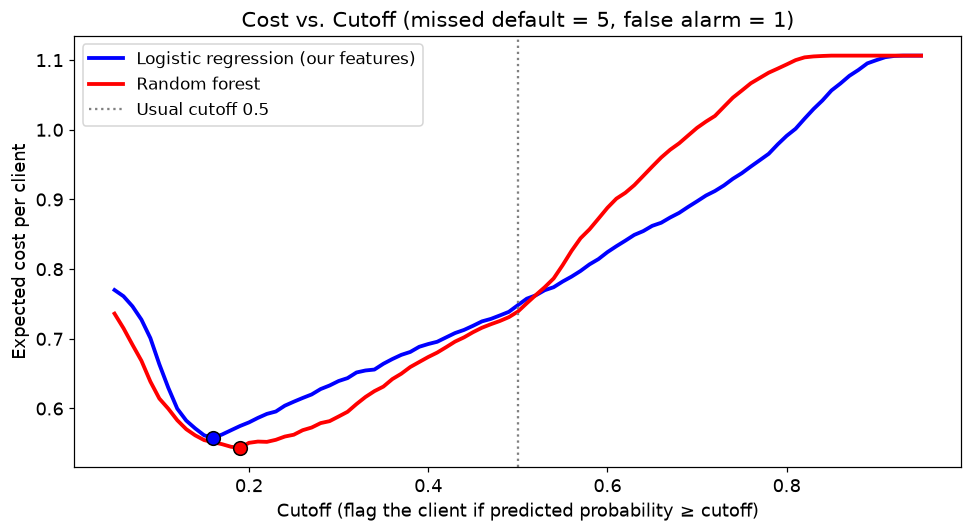

In [7]:
COST_MISS = 5
COST_FALSE_ALARM = 1
cutoffs = np.round(np.arange(0.05, 0.96, 0.01), 2)

def cost_at_each_cutoff(y, prob, cost_miss, cost_false_alarm):
    costs = []
    for t in cutoffs:
        pred = (prob >= t).astype(int)
        missed = ((pred == 0) & (y == 1)).sum()
        false_alarms = ((pred == 1) & (y == 0)).sum()
        costs.append((cost_miss * missed + cost_false_alarm * false_alarms) / len(y))
    return np.array(costs)

best_cutoff = {}
plt.figure(figsize=(9, 5))
for name, color in [(LOGIT, "blue"), (RF, "red")]:
    costs = cost_at_each_cutoff(oof["y"].to_numpy(), oof[name].to_numpy(), COST_MISS, COST_FALSE_ALARM)
    best_cutoff[name] = cutoffs[costs.argmin()]
    plt.plot(cutoffs, costs, color=color, linewidth=2.5, label=name)
    plt.scatter(best_cutoff[name], costs.min(), color=color, s=80, zorder=3, edgecolor="black")
    print(name, " best cutoff =", best_cutoff[name], " cost per client =", round(costs.min(), 3))
plt.axvline(0.5, color="gray", linestyle=":", label="Usual cutoff 0.5")
plt.xlabel("Cutoff (flag the client if predicted probability ≥ cutoff)")
plt.ylabel("Expected cost per client")
plt.title("Cost vs. Cutoff (missed default = 5, false alarm = 1)")
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "cost_vs_threshold.png", dpi=150)
plt.show()

The lowest expected cost is at a cutoff of **0.16** for the logistic regression and **0.19** for the
random forest, much lower than 0.5.

This matches what theory says. If the probabilities are accurate, flagging a client is worth it when
p × 5 > (1 − p) × 1, which works out to **p > 1/6 ≈ 0.17**. Our data-driven cutoff landed right next to it.
The curve is also pretty flat between about 0.13 and 0.20, so the exact value isn't critical.

### Test-set results at 0.5 vs. the cost-based cutoff

In [8]:
rows = {}
for name in [LOGIT, RF]:
    for t in [0.5, best_cutoff[name]]:
        r = results_at(y_test, test_pred[name], t)
        pred = (test_pred[name] >= t).astype(int)
        missed = ((pred == 0) & (y_test == 1)).sum()
        false_alarms = ((pred == 1) & (y_test == 0)).sum()
        r["cost_per_client"] = (COST_MISS * missed + COST_FALSE_ALARM * false_alarms) / len(y_test)
        rows[name + " @ " + str(t)] = r
cutoff_compare = pd.DataFrame(rows).T[["precision", "recall", "f1", "share_flagged", "cost_per_client"]]
cutoff_compare.round(3).to_csv(TABLE_DIR / "test_cutoff_comparison.csv")
cutoff_compare.round(3)

,precision,recall,f1,share_flagged,cost_per_client
Logistic regression (our features) @ 0.5,0.654,0.338,0.445,0.114,0.772
Logistic regression (our features) @ 0.16,0.381,0.711,0.496,0.413,0.575
Random forest @ 0.5,0.652,0.346,0.452,0.118,0.764
Random forest @ 0.19,0.400,0.696,0.508,0.385,0.567


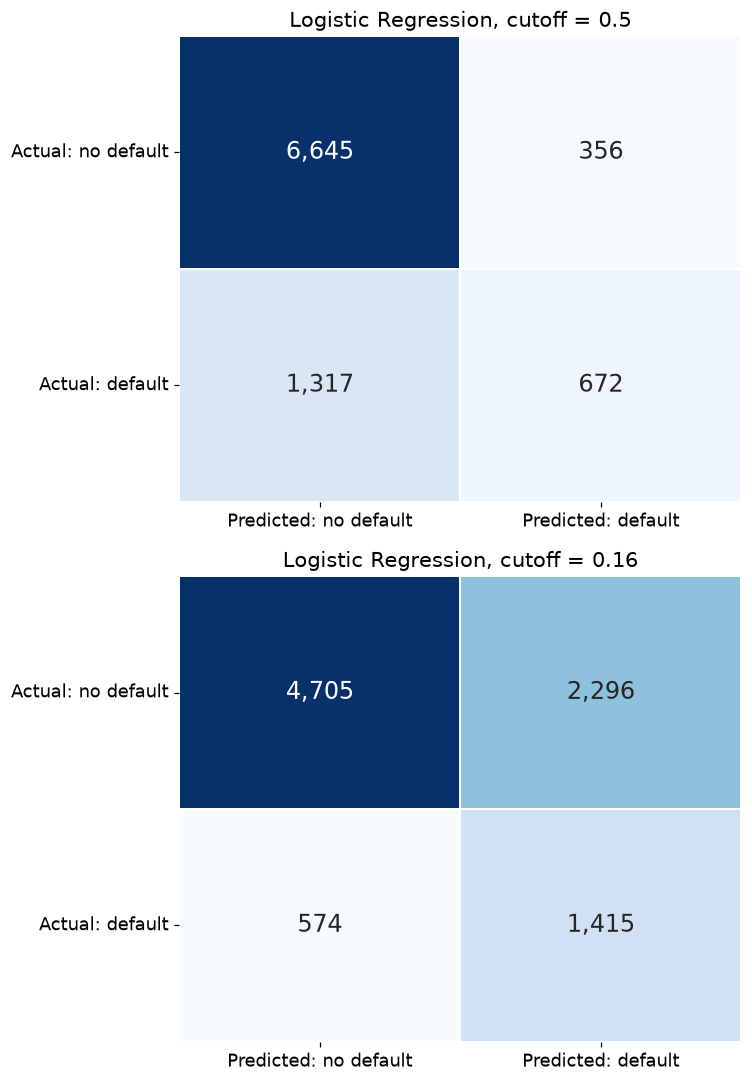

In [9]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

fig, axes = plt.subplots(2, 1, figsize=(7, 10))
for ax, t in zip(axes, [0.5, best_cutoff[LOGIT]]):
    cm = confusion_matrix(y_test, (test_pred[LOGIT] >= t).astype(int))
    sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax,
                annot_kws={"size": 16}, linewidths=1, linecolor="white")
    ax.set_xticklabels(["Predicted: no default", "Predicted: default"])
    ax.set_yticklabels(["Actual: no default", "Actual: default"], rotation=0)
    ax.set_title("Logistic Regression, cutoff = " + str(t))
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrices_logit.png", dpi=150)
plt.show()

Moving the logistic regression's cutoff from 0.5 to 0.16 on the test set:

- **Recall goes from 34% to 71%**, so we catch about twice as many defaulters.
- **Precision drops from 65% to 38%**, so more of the flagged clients are false alarms.
- **The share of clients flagged goes from 11% to 41%.**
- **Expected cost per client drops from 0.77 to 0.58, about 25% lower.**

The random forest at its own cutoff (0.19) costs 0.567 per client vs. 0.575 for the logistic regression,
about 1.4% lower.

## 6. How much does the cost assumption matter?

In [10]:
rows = []
for ratio in [2, 3, 5, 10]:
    costs = cost_at_each_cutoff(oof["y"].to_numpy(), oof[LOGIT].to_numpy(), ratio, 1)
    t = cutoffs[costs.argmin()]
    r = results_at(y_test, test_pred[LOGIT], t)
    rows.append({"cost ratio (miss : false alarm)": str(ratio) + " : 1", "best cutoff": t,
                 "theory 1/(1+ratio)": round(1 / (1 + ratio), 2), "share_flagged": r["share_flagged"],
                 "recall": r["recall"], "precision": r["precision"]})
sensitivity = pd.DataFrame(rows).set_index("cost ratio (miss : false alarm)")
sensitivity.round(3).to_csv(TABLE_DIR / "cutoff_sensitivity.csv")
sensitivity.round(2)

,best cutoff,theory 1/(1+ratio),share_flagged,recall,precision
cost ratio (miss : false alarm),,,,,
2 : 1,0.34,0.33,0.16,0.43,0.58
3 : 1,0.23,0.25,0.25,0.55,0.49
5 : 1,0.16,0.17,0.41,0.71,0.38
10 : 1,0.11,0.09,0.76,0.92,0.27


The cost ratio matters a lot. If a missed default only costs twice as much as a false alarm, the best
cutoff is **0.34**: we flag 16% of clients and catch 43% of defaulters. At 10 : 1 the cutoff drops to
**0.11**, and we flag 76% of clients to catch 92% of defaulters. Each time, the cutoff is close to the
theory value 1 / (1 + ratio).

**The bank should plug in its own cost numbers.** The model stays the same; only the cutoff changes.

## 7. Does the model sort clients well? Risk deciles
We sort the test clients into 10 equal groups by predicted probability, from lowest risk (1) to highest
(10). For each group we compare the **actual** default rate (bars) with the model's **average predicted**
probability (dots). If the dots sit on top of the bars, the probabilities can be trusted as they are.

                                    actual  predicted  defaulters
Logistic regression (our features)                               
1                                     0.06       0.07          55
2                                     0.07       0.09          61
3                                     0.10       0.11          86
4                                     0.11       0.12          97
5                                     0.16       0.14         145
6                                     0.18       0.15         158
7                                     0.20       0.18         181
8                                     0.26       0.23         238
9                                     0.41       0.39         368
10                                    0.67       0.73         600

Share of all defaulters in the top 2 deciles = 0.49
Share of all defaulters in the top 3 deciles = 0.61


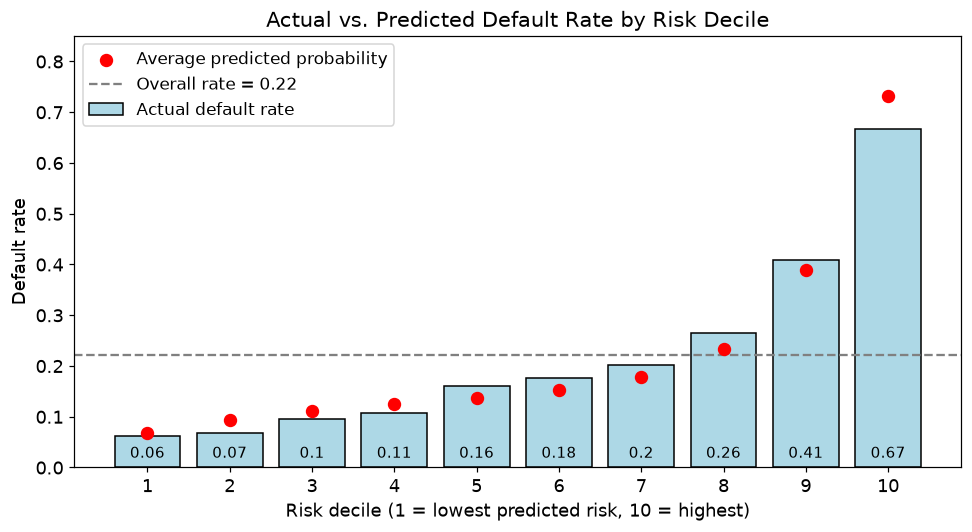

In [11]:
deciles = pd.qcut(test_pred[LOGIT].rank(method="first"), 10, labels=range(1, 11))
by_decile = test_pred.groupby(deciles, observed=True).agg(actual=("y", "mean"), predicted=(LOGIT, "mean"),
                                                        defaulters=("y", "sum"))
print(by_decile.round(2))
print()
print("Share of all defaulters in the top 2 deciles =", round(by_decile["defaulters"].iloc[-2:].sum() / y_test.sum(), 2))
print("Share of all defaulters in the top 3 deciles =", round(by_decile["defaulters"].iloc[-3:].sum() / y_test.sum(), 2))

x = np.arange(1, 11)
plt.figure(figsize=(9, 5))
plt.bar(x, by_decile["actual"], color="lightblue", edgecolor="black", label="Actual default rate")
plt.scatter(x, by_decile["predicted"], color="red", s=60, zorder=3, label="Average predicted probability")
for i, v in zip(x, by_decile["actual"]):
    plt.text(i, 0.012, str(round(v, 2)), ha="center", va="bottom", fontsize=10)
plt.axhline(y_test.mean(), color="gray", linestyle="--", label="Overall rate = " + str(round(y_test.mean(), 2)))
plt.xticks(x)
plt.ylim(0, 0.85)
plt.xlabel("Risk decile (1 = lowest predicted risk, 10 = highest)")
plt.ylabel("Default rate")
plt.title("Actual vs. Predicted Default Rate by Risk Decile")
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "default_rate_by_risk_decile.png", dpi=150)
plt.show()

The model sorts clients well. The **lowest-risk 10% default only 6%** of the time, while the
**highest-risk 10% default 67%** of the time, about 3 times the overall rate. The **top two deciles (20% of
clients) contain 49% of all defaulters**, and the top three contain 61%.

The red dots sit close to the tops of the bars, so the predicted probabilities are about right. The
biggest gap is in the riskiest group, where the model predicts 0.73 and the actual rate is 0.67.

## 8. What this means for a lender
The logistic regression at the cost-based cutoff, scaled to 1,000 clients:

In [12]:
pred = (test_pred[LOGIT] >= best_cutoff[LOGIT]).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
scale = 1000 / len(y_test)

print("Out of 1,000 clients:")
print("  Actual defaulters =", round((tp + fn) * scale))
print("  Flagged by the model =", round((tp + fp) * scale))
print("  Defaulters caught =", round(tp * scale))
print("  Defaulters missed =", round(fn * scale))
print("  Good clients flagged (false alarms) =", round(fp * scale))
print("  Good clients left alone =", round(tn * scale))

Out of 1,000 clients:
  Actual defaulters = 221
  Flagged by the model = 413
  Defaulters caught = 157
  Defaulters missed = 64
  Good clients flagged (false alarms) = 255
  Good clients left alone = 523


Out of every 1,000 clients, about 221 will default. The model flags 413 of them. It catches **157** of
the defaulters and misses 64. The price is about 255 false alarms, which is why the bank should use
low-cost actions (a reminder, a call) for most flagged clients, and save stronger actions like lowering a
limit for the top-risk decile.

## 9. Summary

| | Logistic regression (our features) | Random forest |
|---|---|---|
| Test ROC-AUC (95% CI) | 0.764 (0.751 to 0.776) | 0.773 (0.761 to 0.785) |
| Cost-based cutoff (5 : 1) | 0.16 | 0.19 |
| Recall at that cutoff | 71% | 70% |
| Precision at that cutoff | 38% | 40% |
| Expected cost per client | 0.575 | 0.567 |
| Can it explain its decisions? | Yes: odds ratios, P-values, CIs | Only roughly (feature importance) |

**Why we recommend the logistic regression** (the same question as in Module 5: why choose the
explainable model when a black-box model is a bit more accurate?):

- The random forest is better by about **0.01 AUC** and **1.4% in cost**. That's real, but small.
- The logistic regression can say **why** a client is risky: "2+ months late in September multiplies the
  odds by about 6." A bank can check that, explain it to the client, and show it to regulators.
- Lenders often have to give a reason when they turn someone down or lower a limit. A random forest
  averages 300 trees, so there's no simple reason to give.
- We'd still keep the random forest as a benchmark, to notice if the simple model starts falling behind.

**Main findings**
1. **Recent repayment status is the strongest warning sign.** 2+ months late in September multiplies the
   odds of default by about 6, and each earlier late month by about 1.3.
2. **Credit limit and payment amounts matter, but less.** Higher limits and bigger payments both lower risk.
3. **Demographics add almost nothing.** Taking out sex, marital status and age changes the AUC by 0.0001.
4. **The cutoff matters as much as the model.** Moving from 0.5 to 0.16 doubles the share of defaulters
   caught and lowers expected cost by about 25%.